# The validation battery on a ladder of models: discrimination, calibration and stability

**Question:** When the same battery of tests is run on the whole ladder of models, which family of tests notices which kind of problem (ranking, level, fit or stability of the population), and where does a model that looks sound on one family fail another?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic, and notebook 04 of topic 01
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- read the committed battery of C01, 187 test rows on eight models, as one table, and say which test ids carry a threshold and which only describe;
- call the engine's discrimination, calibration and stability tests on the committed cards, grades and reliability bins, and read the light each one gives;
- open the Hosmer-Lemeshow test on ten reliability bins and read the reliability diagram it summarises;
- see which tests notice a drift of the inputs and which a change of the default rate, and why a model can be green on one family and amber on another.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation.calibration import pd_brier, pd_chi2_grades, pd_ece, pd_hosmer_lemeshow
from riskvalidation.validation.calibration import pd_jeffreys, pd_jeffreys_grades, pd_spiegelhalter, pd_traffic_lights
from riskvalidation.validation.discrimination import disc_auc_vs_initial, disc_delong
from riskvalidation.validation.stability import psi_benchmark

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The case is C01 again: the 9,000 held-out Taiwan cards scored by the eight models of the ladder (UCI Taiwan credit-card file, Yeh, 2009; owner: UCI Machine Learning Repository; CC BY 4.0, licence class `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). Three committed files hold the battery:

- `data/derived/C01/holdout.json`: the ladder, the battery (`tests`, one row per test, model and segment), and per model the grade table, the reliability bins and the ROC; plus a 50-card sample scored by two models.
- `data/derived/C01/drift-moderate.json` and `data/derived/C01/prior-shift.json`: the same models and battery on the same cards after a **synthetic perturbation of the evaluation set only** (a moderate drift of the inputs, a default rate multiplied by 1.5). The models are not refitted; the perturbation is a stress for the tests, not data.

The next cell loads the three files and prints the size of each evaluation set.

In [2]:
# Load the three committed batteries of case C01 (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
drift = json.loads((derived / "drift-moderate.json").read_text(encoding="utf-8"))
prior = json.loads((derived / "prior-shift.json").read_text(encoding="utf-8"))
tests = holdout["tests"]
rungs = holdout["outputs"]["rungs"]
ladder = [m["id"] for m in holdout["model"]]
sample = holdout["outputs"]["sample"]
policy = rv.default_policy()
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
print("models:", ladder)
for name, doc in zip(["holdout", "drift", "default-rate shift"], (holdout, drift, prior)):
    out = doc["outputs"]
    print("evaluation sets, cards and defaults:", name, out["n"], out["defaults"], len(doc["tests"]))
print("baked by riskvalidation", holdout["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

models: ['P0-constant', 'P0-single', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm', 'P4-xgboost']
evaluation sets, cards and defaults: holdout 9000 1991 187
evaluation sets, cards and defaults: drift 9000 2316 186
evaluation sets, cards and defaults: default-rate shift 9000 2986 186
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: one table of tests, three kinds of row

Every row of `tests` is one `TestResult` of the engine: a test id, a model, a segment, the statistic, the p-value or the metric, and the light the policy gave it. The **segment** says what the row is about: `portfolio` for the whole holdout, a grade (`G05`, `G06` and so on) for the cards of one grade, and `characteristic:<name>` for one input variable of the stability tests. The **policy** decides which tests have a light. A test with a threshold is coloured from its p-value (amber below 0.05, red below 0.01 in the default policy); a descriptive test (AUC, KS, Brier, ECE) measures and gets no light, because the ECB instructions and the working paper behind them give no threshold for it. The cell counts the committed rows of the eight models by test id and by kind of segment.

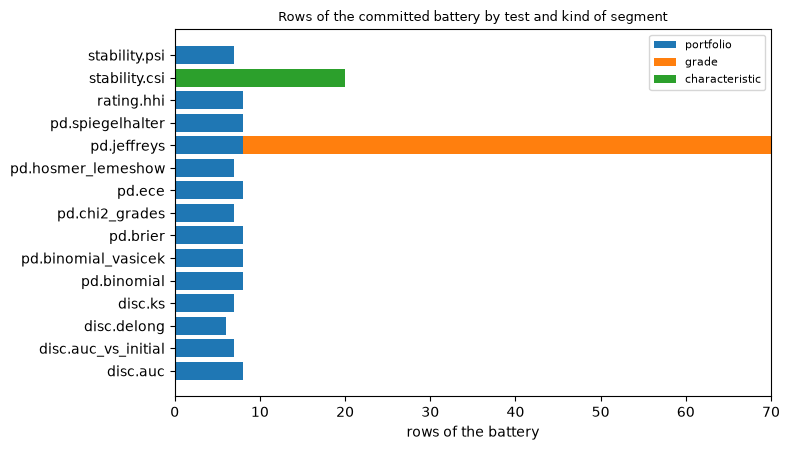

test ids with a threshold in the default policy: 11 of 15
rows in total: 187
rows by kind (portfolio, grade, characteristic): [105  62  20]


In [3]:
# Count the committed rows by test id and by kind of segment, and the test ids that hold a threshold
ids = sorted({t["test_id"] for t in tests})
counts = np.zeros((len(ids), 3), dtype=int)
for t in tests:
    s = t["segment"]
    k = 0 if s == "portfolio" else (2 if s.startswith("characteristic:") else 1)
    counts[ids.index(t["test_id"]), k] += 1
fig, ax = plt.subplots(figsize=(8, 4.6))
left = np.zeros(len(ids))
for k, label in enumerate(["portfolio", "grade", "characteristic"]):
    ax.barh(ids, counts[:, k], left=left, label=label)
    left += counts[:, k]
ax.set_xlabel("rows of the battery")
ax.set_title("Rows of the committed battery by test and kind of segment", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
with_threshold = sum(i in policy.thresholds for i in ids)
print("test ids with a threshold in the default policy:", with_threshold, "of", len(ids))
print("rows in total:", len(tests))
print("rows by kind (portfolio, grade, characteristic):", counts.sum(axis=0))

There are 187 rows, 105 at portfolio level, 62 at grade level (the Jeffreys test of each grade) and 20 for the characteristic stability of the inputs, over 15 test ids, 11 of which hold a threshold. The figure also shows the weight of each family: the level and fit tests dominate the count, discrimination appears once per model, and stability is the 20 variable rows plus one population row. What the count does not show is whether a row is informative. A grey, descriptive row can never turn a model red, so reading a battery by its lights alone ignores AUC and KS by design.

### Step 2: discrimination, the tests that compare models

The first family asks whether the PD ranks defaulters above non-defaulters. The AUC is descriptive. The **DeLong test** (DeLong, DeLong and Clarke-Pearson, 1988) compares the AUC of two models scored on the same cards, whose estimates are correlated, with $z = (\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2)/\sqrt{\widehat{\mathrm{Var}}(\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2)}$ and a two-sided p-value on a standard normal. The **AUC against development** asks whether the AUC now has fallen below the one measured when the model was built, a one-sided question. The cell calls both on the 50-card sample, where two models are scored on the same cards: the explainable boosting machine against the scorecard, and the scorecard against its development AUC with the variance the committed row holds.

In [4]:
# The engine's discrimination tests on the 50 cards: DeLong between two models, and the AUC against development
y50 = np.array(sample["targets"])
pd50 = np.array(sample["scorecard_pd"])
ebm50 = np.array(sample["ebm_logit"])
duo = disc_delong(ebm50, pd50, y50, policy=policy, model_id="P3-ebm")
dev = next(t for t in tests if t["test_id"] == "disc.auc_vs_initial" and t["model_id"] == "P1-scorecard")
e = dev["extras"]
small = disc_auc_vs_initial(e["auc_initial"], pd50, y50, auc_initial_variance=e["auc_initial_variance"],
                            policy=policy, model_id="P1-scorecard")
print("DeLong on 50 cards, EBM against scorecard: z and p:", round(duo.statistic, 2), round(duo.p_value, 3))
print("AUC against development on 50 cards: p and light:", round(small.p_value, 4), LIGHT[small.light.value])

DeLong on 50 cards, EBM against scorecard: z and p: -0.17 0.866
AUC against development on 50 cards: p and light: 0.5476 green


On 50 cards the engine finds no difference between the explainable boosting machine and the scorecard (z of -0.17, p of 0.866), and the AUC of the scorecard is not below its development AUC (p of 0.5476, green). Nothing here is evidence of equivalence: with 15 defaulters, a test that does not reject says only that the sample is too small to tell. The same tests on 9,000 cards are the ones the battery commits, and the next cell draws them.

### Step 3: the eight models on the 9,000 held-out cards

The committed AUC rows carry a 95% interval, and the DeLong rows compare each challenger with the scorecard on the same 9,000 cards. The figure draws the AUC of the eight rungs with its interval, with a dashed line at the scorecard's value, and the cell prints each model's AUC and the DeLong p-value against the scorecard. The question it answers is whether a richer model ranks better, and whether the intervals, which overlap, can be trusted to say so.

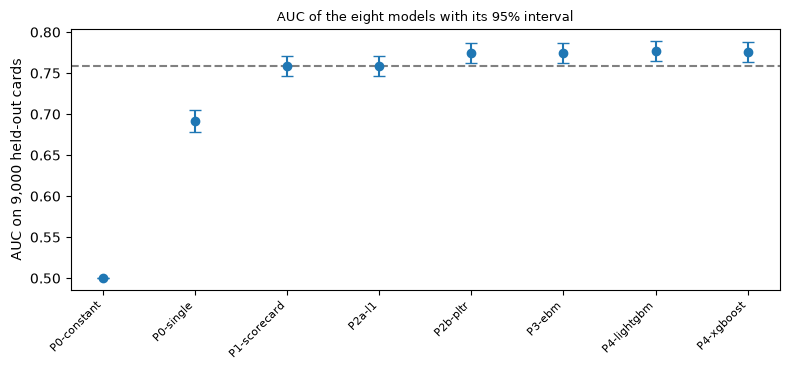

P0-constant AUC 0.5 DeLong p None
P0-single AUC 0.6917 DeLong p 1.26e-40
P1-scorecard AUC 0.7587 DeLong p None
P2a-l1 AUC 0.7587 DeLong p 0.0884
P2b-pltr AUC 0.7749 DeLong p 2.58e-11
P3-ebm AUC 0.7746 DeLong p 2.74e-10
P4-lightgbm AUC 0.777 DeLong p 6.53e-13
P4-xgboost AUC 0.7755 DeLong p 2.18e-12


In [5]:
# The AUC of the eight models on the 9000 held-out cards with its committed 95% interval
auc_rows = {t["model_id"]: t for t in tests if t["test_id"] == "disc.auc"}
mid = [auc_rows[m]["metric"] for m in ladder]
low = [auc_rows[m]["metric"] - auc_rows[m]["extras"]["ci95_low"] for m in ladder]
high = [auc_rows[m]["extras"]["ci95_high"] - auc_rows[m]["metric"] for m in ladder]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(range(len(ladder)), mid, yerr=[low, high], fmt="o", capsize=4)
ax.axhline(auc_rows["P1-scorecard"]["metric"], color="gray", linestyle="--")
ax.set_xticks(range(len(ladder)), ladder, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("AUC on 9,000 held-out cards")
ax.set_title("AUC of the eight models with its 95% interval", fontsize=9)
fig.tight_layout()
plt.show()
for m in ladder:
    row = next((t for t in tests if t["test_id"] == "disc.delong" and t["model_id"] == m), None)
    p_value = None if row is None else float(f"{row['p_value']:.3g}")
    print(m, "AUC", round(auc_rows[m]["metric"], 4), "DeLong p", p_value)

The scorecard and the penalised logistic regression tie at 0.7587 (DeLong p of 0.0884, no difference), the one-variable baseline sits at 0.6917 (p of 1.26e-40), and the penalised trees, the boosting machine and the two boosted-tree models reach 0.7746 to 0.777, each different from the scorecard with p-values from 2.58e-11 to 6.53e-13. The intervals of the five richer models all overlap with the scorecard's, and yet the paired test separates them, because the two models score the same cards and their errors are strongly correlated. Comparing intervals is the wrong test for a paired comparison; the gain of about 0.016 to 0.018 AUC points is small but real.

### Step 4: calibration, the level and the fit

The second family asks whether the PDs have the right size, and it asks two different questions. The **level** test asks whether the average PD is right: the Jeffreys test (Brown, Cai and DasGupta, 2001) takes the cards, the defaults and the mean PD and is one-sided, rejecting only when defaults exceed what the PD allows. The **fit** tests ask whether the PD fits group by group: the chi-square over the grades (BCBS, 2005) can fail even when the average is right, because a PD too high for some grades can offset one too low for others. The cell runs the Jeffreys test on each of the eight grades of the scorecard, the chi-square over all grades and the traffic-light test, and draws the p-value of each grade coloured by the light.

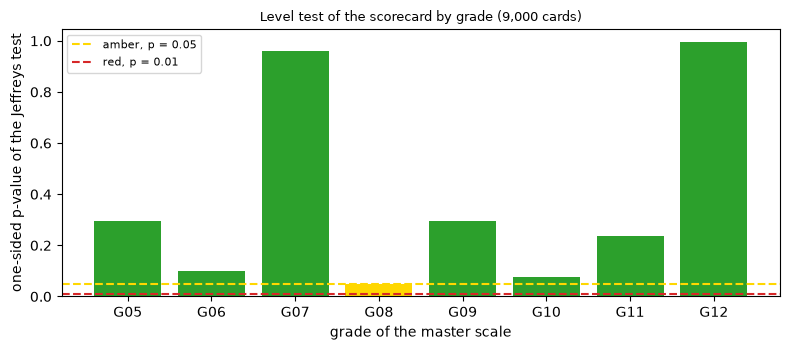

chi-square over grades: p and light: 0.0264 amber
portfolio level, Jeffreys p and light: 0.3095 green
traffic-light colours by grade: ['yellow', 'orange', 'green', 'red', 'yellow', 'orange', 'yellow', 'green']


In [6]:
# The engine's one-sided Jeffreys test per grade, the chi-square over grades and the traffic light of the scorecard
grades = [g for g in rungs["P1-scorecard"]["grades"] if g["n"] > 0]
n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
names_g = [g["grade"] for g in grades]
per_grade = pd_jeffreys_grades(n_g, d_g, pd_g, grades=names_g, policy=policy, model_id="P1-scorecard")
chi = pd_chi2_grades(n_g, d_g, pd_g, policy=policy, model_id="P1-scorecard", segment="portfolio")
light = pd_traffic_lights(n_g, d_g, pd_g, policy=policy, model_id="P1-scorecard", segment="portfolio")
colors = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgray"}
fig, ax = plt.subplots(figsize=(8, 3.6))
by_grade, portfolio = per_grade[:-1], per_grade[-1]
ax.bar(names_g, [r.p_value for r in by_grade], color=[colors[r.light.value] for r in by_grade])
ax.axhline(0.05, color="gold", linestyle="--", label="amber, p = 0.05")
ax.axhline(0.01, color="tab:red", linestyle="--", label="red, p = 0.01")
ax.set_xlabel("grade of the master scale")
ax.set_ylabel("one-sided p-value of the Jeffreys test")
ax.set_title("Level test of the scorecard by grade (9,000 cards)", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("chi-square over grades: p and light:", round(chi.p_value, 4), LIGHT[chi.light.value])
print("portfolio level, Jeffreys p and light:", round(portfolio.p_value, 4), LIGHT[portfolio.light.value])
print("traffic-light colours by grade:", light.extras["colours"])

Grade G08 is amber (p of 0.0494) and the rest are green, but the portfolio level has a Jeffreys p of 0.3095 (green): on average the PD is not too low. The fit is a different story. The chi-square over the grades is amber (p of 0.0264), and the traffic-light test colours the grades yellow, orange, green, red, yellow, orange, yellow and green: grade G08, the largest with 3,101 cards, shows more defaults than its PD admits, and G12, the riskiest, fewer. The portfolio is right on average and wrong in a way that matters by grade, and a validator who ran only the level test would miss it.

### Step 5: Hosmer-Lemeshow, opened

Hosmer-Lemeshow sorts the cards by PD, cuts them into $G$ groups of equal size and compares, in group $g$ with $m_g$ cards, the observed defaults $O_g$ with the expected defaults $E_g$, the sum of the PDs of the group (Hosmer and Lemeshow, 1980):

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

with a $\chi^2$ reference of $G$ degrees of freedom when the PDs were set before the outcomes, as for a validation sample. The committed reliability bins are such groups: ten bins of 900 cards, each with its mean PD and observed rate. The cell rebuilds 9,000 cards from them (the PD of the bin for each card, the observed number of defaults in the bin), calls `pd_hosmer_lemeshow`, `pd_spiegelhalter`, `pd_brier` and `pd_ece` on the scorecard and on the monotone LightGBM model, and draws the reliability diagram of each.

P1-scorecard Hosmer-Lemeshow, p and light: 0.015 amber
Spiegelhalter, p: 0.035
Brier and ECE of the rebuilt cards: 0.1404 0.0155
P4-lightgbm Hosmer-Lemeshow, p and light: 0.008 red
Spiegelhalter, p: 0.126
Brier and ECE of the rebuilt cards: 0.1376 0.0134


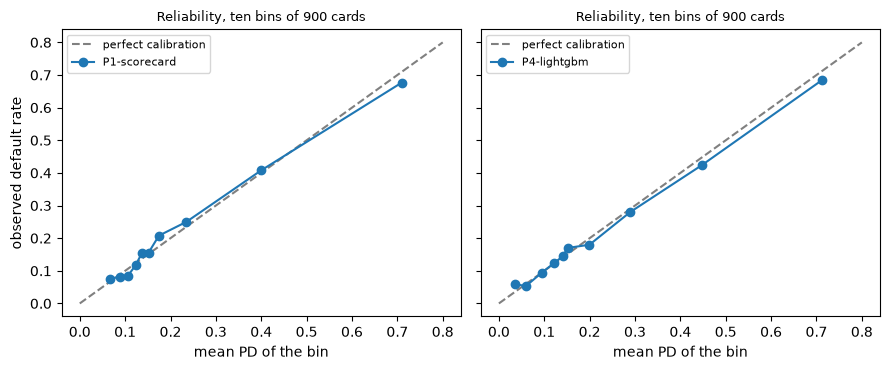

In [7]:
# Rebuild 9000 cards from the ten reliability bins and run Hosmer-Lemeshow, Spiegelhalter, Brier and ECE on them
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, rung in zip(axes, ("P1-scorecard", "P4-lightgbm")):
    bins_ = rungs[rung]["reliability"]
    pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
    hit = [int(round(b["dr"] * b["n"])) for b in bins_]
    flags = np.concatenate([np.r_[np.ones(h), np.zeros(b["n"] - h)] for b, h in zip(bins_, hit)])
    hl = pd_hosmer_lemeshow(flags, pd_cards, groups=10, policy=policy, model_id=rung, segment="portfolio")
    sp = pd_spiegelhalter(flags, pd_cards, policy=policy, model_id=rung, segment="portfolio")
    brier = pd_brier(flags, pd_cards, policy=policy, model_id=rung, segment="portfolio")
    ece = pd_ece(flags, pd_cards, policy=policy, model_id=rung, segment="portfolio")
    print(rung, "Hosmer-Lemeshow, p and light:", round(hl.p_value, 4), LIGHT[hl.light.value])
    print("Spiegelhalter, p:", round(sp.p_value, 3))
    print("Brier and ECE of the rebuilt cards:", round(brier.metric, 4), round(ece.metric, 4))
    ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="perfect calibration")
    ax.plot([b["pd"] for b in bins_], [b["dr"] for b in bins_], marker="o", label=rung)
    ax.set_xlabel("mean PD of the bin")
    ax.set_title("Reliability, ten bins of 900 cards", fontsize=9)
    ax.legend(fontsize=8)
axes[0].set_ylabel("observed default rate")
fig.tight_layout()
plt.show()

The engine returns a Hosmer-Lemeshow p-value of 0.015 for the scorecard (amber), the committed value, and 0.008 for LightGBM (red): the better ranker is the worse fit by this test, which echoes the chi-square over grades of notebook 06. The Brier score of the rebuilt cards, 0.1404, is slightly above the committed 0.1393 and the Spiegelhalter p-value, 0.035, differs from the committed 0.0219, because every card of a bin shares one PD in the rebuilt vector and the real PDs vary inside a bin; the ECE, 0.0155, and the Hosmer-Lemeshow statistic are functions of the bin means and do not suffer from that. The diagrams show both models close to the diagonal, with departures in the middle bins where a few hundred defaults decide the test.

### Step 6: stability, the population against development

The third family compares the population now with the population at development. The population stability index (PSI) of the PD takes ten bins fixed on the development cards (here the 16,800 training cards) and compares the share of the holdout cards in each, $\mathrm{PSI} = \sum_i (a_i - e_i)\ln(a_i/e_i)$ with $e_i$ and $a_i$ the shares at development and now. With a chi-square benchmark (Yurdakul and Naranjo, 2020) the PSI has a critical value that depends only on the two sample sizes and the number of bins, which the engine's `psi_benchmark` returns. The cell computes it for 16,800 development and 9,000 current cards, sets it beside the committed PSI of the scorecard, and draws the contribution of each decile to it.

PSI of the scorecard and its 5% critical value: 0.000952 0.00289
critical value committed by the pipeline: 0.00289


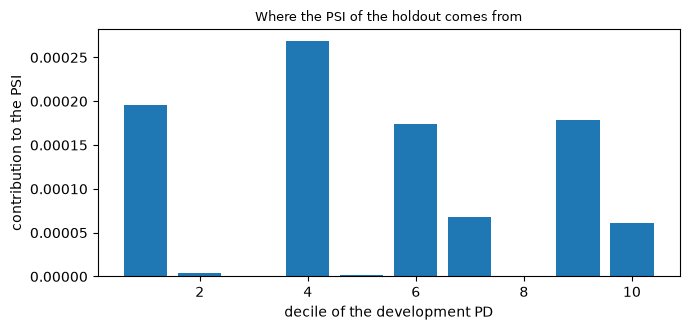

In [8]:
# The engine's critical PSI for these sample sizes, against the PSI of the scorecard and its contributions by decile
psi_row = next(t for t in tests if t["test_id"] == "stability.psi" and t["model_id"] == "P1-scorecard")
extras = psi_row["extras"]
critical = psi_benchmark(extras["n"], extras["m"], extras["bins"])
print("PSI of the scorecard and its 5% critical value:", round(psi_row["metric"], 6), round(critical, 5))
print("critical value committed by the pipeline:", round(extras["benchmark_05"], 5))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(1, len(extras["contributions"]) + 1), extras["contributions"], color="tab:blue")
ax.set_xlabel("decile of the development PD")
ax.set_ylabel("contribution to the PSI")
ax.set_title("Where the PSI of the holdout comes from", fontsize=9)
fig.tight_layout()
plt.show()

The PSI of the scorecard, 0.000952, is a third of the critical value of 0.00289 that the engine computes from the sample sizes, the same 0.00289 the pipeline committed: the holdout has the population of development, as it should, since the split was stratified. The contributions are tiny in every decile, the largest in the fourth, about 0.0003. A PSI that small says there is no drift to see, which makes the next step informative: it asks what the same tests say when there is one.

### Step 7: what each test notices when the cards change

The same scorecard faces three evaluation sets: the holdout as it is, the holdout with a moderate drift of the inputs, and the holdout with the default rate multiplied by 1.5 (2,986 defaults instead of 1,991). The models are not refitted. A battery is useful only if its tests notice different things, and this comparison is the evidence of which notice what. The cell calls the engine's level test, `pd_jeffreys`, on each set from the committed cards, defaults and mean PD, prints the committed p-values of six tests, and draws them on a log scale with the 5% line.

Jeffreys p of the scorecard by evaluation set: [0.31, 0.728, 8.67e-79]
disc.auc_vs_initial [0.226, 0.938, 0.558]
pd.jeffreys [0.31, 0.728, 8.67e-79]
pd.binomial_vasicek [0.454, 0.493, 0.09]
pd.hosmer_lemeshow [0.015, 0.00163, 2.19e-109]
pd.spiegelhalter [0.0219, 0.0115, 6.45e-65]
stability.psi [0.781, 3.35e-36, 2.31e-14]


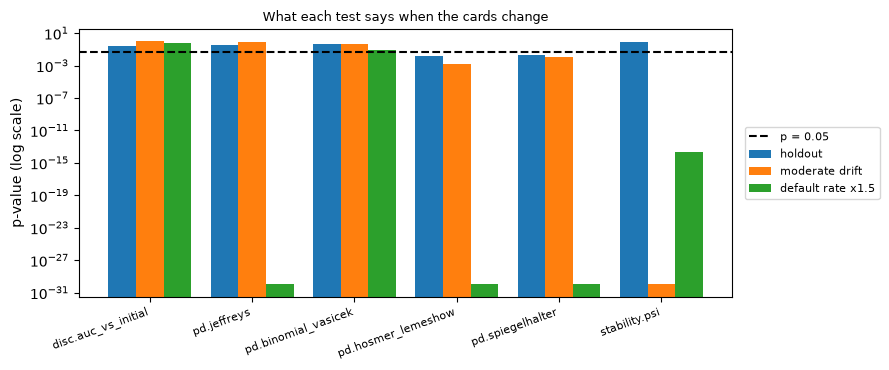

In [9]:
# The engine's level tests on the scorecard for each evaluation set, beside the committed portfolio rows
sets = (holdout, drift, prior)
show = ["disc.auc_vs_initial", "pd.jeffreys", "pd.binomial_vasicek"]
show += ["pd.hosmer_lemeshow", "pd.spiegelhalter", "stability.psi"]
jef = []
for doc in sets:
    bins_ = doc["outputs"]["rungs"]["P1-scorecard"]["reliability"]
    n_all, d_all = doc["outputs"]["n"], doc["outputs"]["defaults"]
    mean_pd = sum(b["n"] * b["pd"] for b in bins_) / sum(b["n"] for b in bins_)
    kw = dict(policy=policy, model_id="P1-scorecard", segment="portfolio")
    jef.append(pd_jeffreys(n_all, d_all, mean_pd, **kw).p_value)
print("Jeffreys p of the scorecard by evaluation set:", [float(f"{p:.3g}") for p in jef])
committed = {}
for i in show:
    rows = [t for doc in sets for t in doc["tests"] if t["test_id"] == i and t["model_id"] == "P1-scorecard"]
    committed[i] = [t["p_value"] for t in rows if t["segment"] == "portfolio"]
    print(i, [float(f"{p:.3g}") for p in committed[i]])
width = 0.27
fig, ax = plt.subplots(figsize=(9, 3.8))
for j, name in enumerate(["holdout", "moderate drift", "default rate x1.5"]):
    values = [committed[i][j] for i in show]
    ax.bar(np.arange(len(show)) + (j - 1) * width, np.maximum(values, 1e-30), width=width, label=name)
ax.set_yscale("log")
ax.axhline(0.05, color="black", linestyle="--", label="p = 0.05")
ax.set_xticks(range(len(show)), show, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("p-value (log scale)")
ax.set_title("What each test says when the cards change", fontsize=9)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

## Results

**Answer:** Each family notices a different problem, and none of them notices all. The battery holds 187 rows, 11 of 15 test ids with a threshold; the AUC family says the richer models rank better (DeLong p of 2.58e-11 for the penalised trees, 6.53e-13 for LightGBM) with an AUC of 0.7587 for the scorecard. The level family is silent about a drift of the inputs and loud about a change of the default rate: the Jeffreys p-value of the scorecard is 0.31 on the holdout, 0.728 under the moderate drift and 8.67e-79 when the default rate rises by half. The fit tests see the drift: Hosmer-Lemeshow gives 0.015 on the holdout (amber, the value the engine returns from the ten reliability bins) and 0.00163 under the drift, and the PSI goes from 0.781 to 3.35e-36, against a critical value of 0.00289 on the holdout. The chi-square over the grades of the scorecard is amber (0.0264) while its portfolio level is green (0.3095).

A model can therefore be green on one family and amber or red on another, for a reason: the scorecard ranks as well as its level is right on average, and its grades fit less well; LightGBM ranks best and fits worst (Hosmer-Lemeshow p of 0.008). The figure of the last step shows it plainly: the bars of the level tests collapse only in the last group, while the fit and stability bars collapse in both.

What this notebook does not show: the characteristic stability rows (20 variables, all green on the holdout), the lights of the other seven models on each family, and anything about the order in time of the cards, since C01 is one snapshot of 2005: the out-of-time question is notebook 04.

## Summary

- One battery, 15 test ids, eight models: portfolio rows carry the headline, grade rows locate the problem, characteristic rows watch the inputs; descriptive rows (AUC, KS, Brier, ECE) never turn a light.
- Discrimination, level, fit and stability are separate families. A paired DeLong test, not overlapping intervals, says whether a challenger ranks better, and a level test cannot see a misfit by grade.
- The engine reproduces a committed row from the numbers the artifact holds: Hosmer-Lemeshow from ten reliability bins, the critical PSI from the two sample sizes, the grade-level and portfolio-level Jeffreys rows.
- Shifted evaluation sets show that the tests notice different things: a drift of the inputs reaches the PSI and the fit tests, a change of the default rate reaches the level tests, and the AUC against development notices neither.

**What to try next.** Replace `P4-lightgbm` by `P3-ebm` in Step 5 and compare the Hosmer-Lemeshow p-value; then continue with notebook 04, which applies the same discipline out of time, on the small-business loans of case C03.

## References

- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial, the Vasicek-adjusted binomial and the chi-square over grades. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 and 2.5.4.1 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients